In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from datetime import datetime
from scipy.stats import norm
from scipy.optimize import brentq
from mpl_toolkits.mplot3d import Axes3D

In [2]:
asset = yf.Ticker("TSLA")
for index in  range(len(asset.options)):
    print(f"{index} {asset.options[index]}")

0 2026-04-15
1 2026-04-17
2 2026-04-20
3 2026-04-24
4 2026-05-01
5 2026-05-08
6 2026-05-15
7 2026-05-22
8 2026-05-29
9 2026-06-18
10 2026-07-17
11 2026-08-21
12 2026-09-18
13 2026-10-16
14 2026-11-20
15 2026-12-18
16 2027-01-15
17 2027-03-19
18 2027-06-17
19 2027-12-17
20 2028-01-21
21 2028-06-16
22 2028-12-15


In [3]:
date = asset.options[12]
expiry = datetime.strptime(date, "%Y-%m-%d")
today = datetime.today()
T = (expiry - today).days / 365

print(f"T: {T:.4f} years")

T: 0.4247 years


In [4]:
S = yf.download("TSLA", period="5d")["Close"]["TSLA"].iloc[-1]

chain = asset.option_chain(date)
calls = chain.calls

print(f"S: ${S:.2f}")
print(calls[['strike', 'lastPrice', 'impliedVolatility']].head(10))

[*********************100%***********************]  1 of 1 completed


S: $364.20
   strike  lastPrice  impliedVolatility
0     5.0     357.95           2.664066
1    10.0     388.50           2.390629
2    15.0     421.02           0.000000
3    20.0     429.13           0.000000
4    30.0     450.85           0.000000
5    35.0     444.10           0.000000
6    40.0     395.20           8.382817
7    45.0     222.55           0.000010
8    50.0     401.33           0.000000
9    60.0     302.00           1.424808


In [5]:
r = yf.download("^TNX", period="5d")["Close"]["^TNX"].iloc[-1] / 100
print(f"r: {r:.4f}")

[*********************100%***********************]  1 of 1 completed

r: 0.0426


In [6]:
def bsm_call(S, K, T, r , sigma):
    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def calc_iv(S, K, T, r, market_price):
    try:
        iv = brentq(lambda sigma: bsm_call(S, K, T, r, sigma) - market_price, 0.001, 10)
        return iv
    except:
        return None

In [7]:
results = []

for _, row in calls.iterrows():
    K = row['strike']
    market_price = row['lastPrice']
    
    if market_price > 0:
        iv = calc_iv(S, K, T, r, market_price)
        if iv is not None:
            results.append({'strike': K, 'iv': iv})

df = pd.DataFrame(results)
print(df)

    strike        iv
0     70.0  6.072603
1     80.0  2.668472
2    115.0  0.993227
3    185.0  0.371131
4    200.0  0.616344
..     ...       ...
95   950.0  0.570564
96   960.0  0.582284
97   970.0  0.575976
98   980.0  0.579331
99   990.0  0.606988

[100 rows x 2 columns]


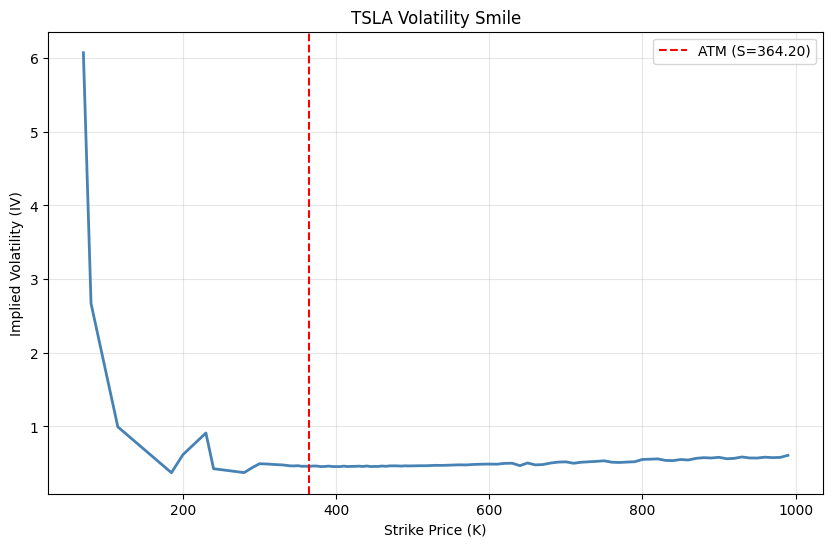

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(df['strike'], df['iv'], color='steelblue', linewidth=2)
plt.axvline(S, color='red', linestyle='--', label=f'ATM (S={S:.2f})')
plt.title("TSLA Volatility Smile")
plt.xlabel("Strike Price (K)")
plt.ylabel("Implied Volatility (IV)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
surface_data = []

for date in asset.options[5:15]: 
    expiry = datetime.strptime(date, "%Y-%m-%d")
    T = (expiry - datetime.today()).days / 365
    
    if T <= 0:
        continue
        
    chain = asset.option_chain(date)
    calls = chain.calls
    
    for _, row in calls.iterrows():
        K = row['strike']
        market_price = row['lastPrice']
        
        if market_price > 0:
            iv = calc_iv(S, K, T, r, market_price)
            if iv is not None and iv < 5:
                surface_data.append({'strike': K, 'T': T, 'iv': iv})

surface_df = pd.DataFrame(surface_data)
print(f"Total data points: {len(surface_df)}")

Total data points: 872


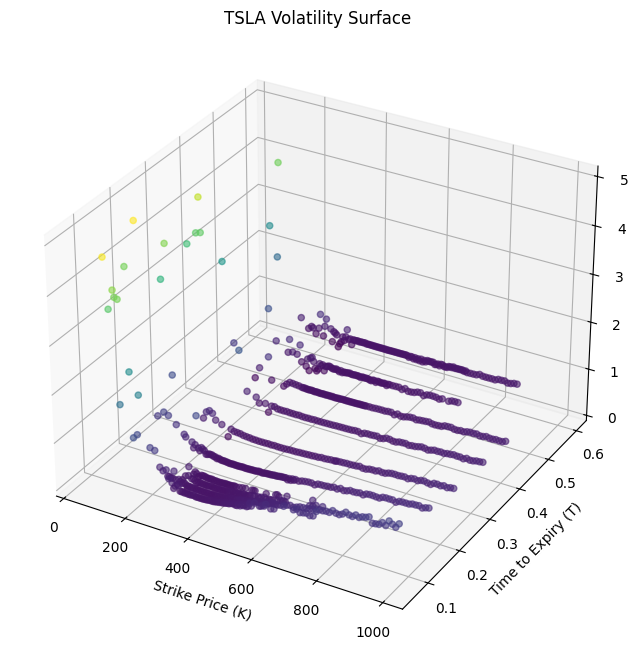

In [13]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(surface_df['strike'], surface_df['T'], surface_df['iv'], 
           c=surface_df['iv'], cmap='viridis', alpha=0.6)

ax.set_xlabel('Strike Price (K)')
ax.set_ylabel('Time to Expiry (T)')
ax.set_zlabel('Implied Volatility (IV)')
ax.set_title('TSLA Volatility Surface')

plt.show()